<b> Заголовок: </b> Исследование данных продаж компьютерных игр в интернет-магазине «Стримчик»

<b> Описание проекта: </b> Игровая индустрия устройчиво занимает одно из самых заинтересованных индустрий в сфере развлечений. Миллионы людей по всему миру покупают себе игры для своего досуга разного жанра и направленностей. Разновидностей игр много, начиная от платформ, на которой создана игра, заканчивая возрастных рейтингом. Множество аспектов определяет успешность игры, а значит и её продаваемость. Для понимания объёмов продаж в последующие года, необходим анализ продаж предыдущих годов, поскольку при правильном определении  закономерностей успешности игр можно будет сделать ставку на потенциально популярный продукт и спланировать рекламные кампании.

<b> Цель исследования: </b> Выявить закономерности успешности игр путём анализа рынка продаж интернет-магазина «Стримчик» за предыдущие годы, на основе, которого спрогнозировать продажи в последующем году.

<b> Ход исследования:</b> 

- Подготовка данных: загрузка и изучение общей информации из представленных датасетов
- Предобработка данных: обработка пропущенных значений и дубликатов, корректировка типа данных
- Исследовательский анализ данных: построение графиков продаж по различным платформам, жанрам, годам для понимания картины задачи и выявления наиболее востребованных жанров и платформ у покупателей
- Портрет пользователя по регионам: выявление наиболее востребованных жанров и платформ у покупателей игр в различных регионах
- Проверка гипотез: проверить гипотезы о равенстве пользовательских рейтингов у игровых платформ XOne и PS3 и жанров Action и Sports

<b> Общий вывод: </b> резюмирование полученных результатов, формулировка ключевых выводов и рекомендаций.

При помощи данного исследования интернет-магазине «Стримчик» сможет спрогнозировать продажи в последующем году и спланировать рекламную компанию на потенциально популярный продукт.

## Шаг первый. Открытие и первичный анализ данных

In [1]:
import pandas as pd
from scipy import stats as st
import matplotlib.pyplot as plt
import math
#Подгружаем библиотеки

In [2]:
try:
    data_raw = pd.read_csv('games.csv')
except:
    print('Не удалось открыть файл')
#Открываем файл

In [3]:
#Изучаем датсет
data_raw.head()

,Name,Platform,Year_of_Release,Genre,NA_sales,EU_sales,JP_sales,Other_sales,Critic_Score,User_Score,Rating
0,Wii Sports,Wii,2006.0,Sports,41.36,28.96,3.77,8.45,76.0,8,E
1,Super Mario Bros.,NES,1985.0,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E
3,Wii Sports Resort,Wii,2009.0,Sports,15.61,10.93,3.28,2.95,80.0,8,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN


In [4]:
data_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16713 non-null  object 
 1   Platform         16715 non-null  object 
 2   Year_of_Release  16446 non-null  float64
 3   Genre            16713 non-null  object 
 4   NA_sales         16715 non-null  float64
 5   EU_sales         16715 non-null  float64
 6   JP_sales         16715 non-null  float64
 7   Other_sales      16715 non-null  float64
 8   Critic_Score     8137 non-null   float64
 9   User_Score       10014 non-null  object 
 10  Rating           9949 non-null   object 
dtypes: float64(6), object(5)
memory usage: 1.4+ MB


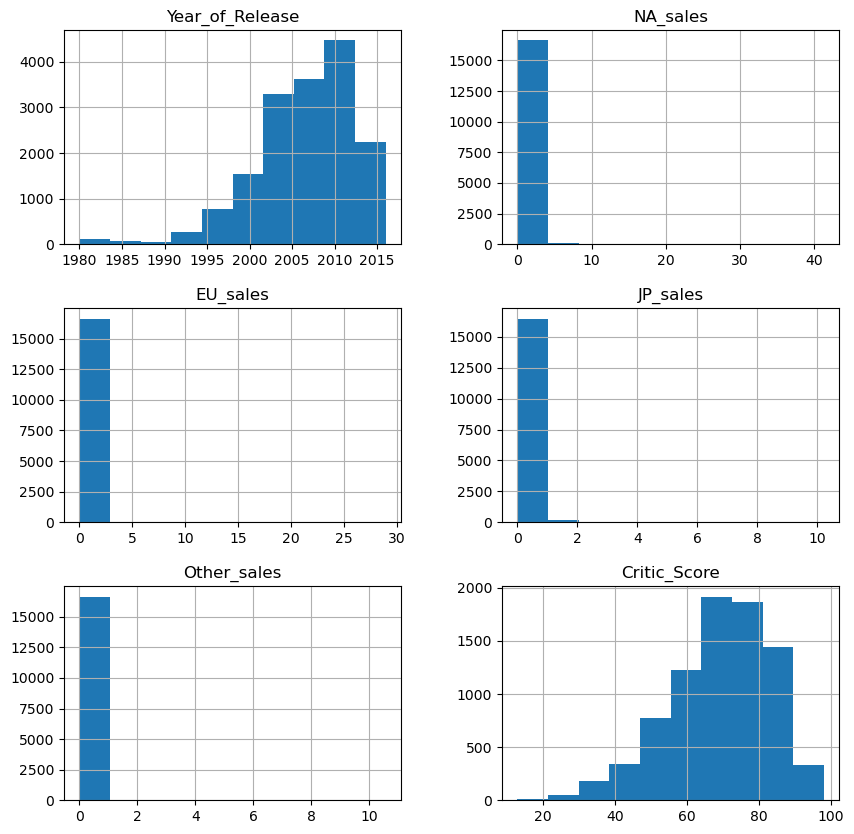

In [5]:
data_raw.hist(figsize=(10,10));

Из информации о датасете видно, что присутствует большое количество пустых строк в отзывах критиков и пользователей.
Из гистограмм можно увидеть, что большая масса игр в датасете выпущена в период от 2000 по 2015 годах, оценки критиков в основном собирают около 70 баллов, а основная масса продаж за все регионы не превалирует за 5 миллионов копий.

## Шаг второй. Предобработка данных

In [6]:
#Изучаем количество пустых строк
data_raw.isna().sum()

Name                  2
Platform              0
Year_of_Release     269
Genre                 2
NA_sales              0
EU_sales              0
JP_sales              0
Other_sales           0
Critic_Score       8578
User_Score         6701
Rating             6766
dtype: int64

In [7]:
#Переименум столбцы в канонический вид
data_raw = data_raw.rename(columns={"Name": "name","Platform": "platform", "Year_of_Release": "year_of_release", "Genre": "genre", "NA_sales": "na_sales"})
data_raw = data_raw.rename(columns={"EU_sales": "eu_sales","JP_sales": "jp_sales", "Other_sales": "other_sales", "Critic_Score": "critic_score", "User_Score": "user_score", "Rating": "rating"})

In [8]:
#Избавимся от двух пустых строк в столбце жанры, так как это количество не существенно для анализа
data = data_raw[~data_raw['genre'].isna()]

In [9]:
#Некоторые игры имеют год выпуска в названии, найдем их и заменим пропуски
list_of_year_name = []
list_of_year = []
for i in data.loc[data['year_of_release'].isna(), 'name']:
    x = i.split()
    try:
        int(x[len(x) - 1])
        if len(x[len(x) - 1]) == 4:
            list_of_year_name.append(i)
            list_of_year.append(x[len(x) - 1])
            data.loc[(data['year_of_release'].isna()) & (data['name'] == i), 'year_of_release'] = float(x[len(x) - 1])
    except:
        pass
        
print(list_of_year_name)
print(list_of_year)

['Madden NFL 2004', 'FIFA Soccer 2004', 'wwe Smackdown vs. Raw 2006', 'NASCAR Thunder 2003', 'Madden NFL 2002', 'NFL GameDay 2003', 'NBA Live 2003', 'All-Star Baseball 2005', 'NBA Live 2003', 'All-Star Baseball 2005', 'Tour de France 2011', 'Sega Rally 2006', 'PDC World Championship Darts 2008', 'Football Manager 2007', 'PDC World Championship Darts 2008']
['2004', '2004', '2006', '2003', '2002', '2003', '2003', '2005', '2003', '2005', '2011', '2006', '2008', '2007', '2008']


In [10]:
#Заменим тип у года релиза, формат в остальных столбцах верный
data = data.loc[~data['year_of_release'].isna()]
data['year_of_release'] = data['year_of_release'].astype('int')

In [11]:
# Код ревьюера
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 16459 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   name             16459 non-null  object 
 1   platform         16459 non-null  object 
 2   year_of_release  16459 non-null  int64  
 3   genre            16459 non-null  object 
 4   na_sales         16459 non-null  float64
 5   eu_sales         16459 non-null  float64
 6   jp_sales         16459 non-null  float64
 7   other_sales      16459 non-null  float64
 8   critic_score     7994 non-null   float64
 9   user_score       9850 non-null   object 
 10  rating           9778 non-null   object 
dtypes: float64(5), int64(1), object(5)
memory usage: 1.5+ MB


In [12]:
data.loc[data['user_score'] == 'tbd', 'user_score'] = float('NaN')
data['rating'] = data['rating'].fillna('unknown')

Заменили пропуски в rating на unknown, чтобы учесть пропуски в дальнейшем анализе, и tbd в user_score на NaN

In [13]:
#Смотрим на оставшиеся пустые строки снова
data.isna().sum()

name                  0
platform              0
year_of_release       0
genre                 0
na_sales              0
eu_sales              0
jp_sales              0
other_sales           0
critic_score       8465
user_score         8987
rating                0
dtype: int64

В столбце rating сделать ничего нельзя так как этот рейтинг устанавливает ESRB, присваивая им возрастную категорию, чего мы сделать не можем не рассмотрев детально каждую из игр

In [14]:
#Смотрим количество явных дубликатов
data.duplicated().sum()

np.int64(0)

In [15]:
data_check = data[['name', 'platform', 'year_of_release']]
data_check[data_check.duplicated()]

,name,platform,year_of_release
16230,Madden NFL 13,PS3,2012


In [16]:
data[data['name'] == 'Madden NFL 13']

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating
507,Madden NFL 13,X360,2012,Sports,2.53,0.15,0.0,0.17,81.0,5.8,E
604,Madden NFL 13,PS3,2012,Sports,2.11,0.22,0.0,0.23,83.0,5.5,E
3986,Madden NFL 13,Wii,2012,Sports,0.47,0.00,0.0,0.03,NaN,7.3,E
5887,Madden NFL 13,PSV,2012,Sports,0.28,0.00,0.0,0.02,63.0,7.3,E
7066,Madden NFL 13,WiiU,2012,Sports,0.21,0.00,0.0,0.02,75.0,6.7,E
16230,Madden NFL 13,PS3,2012,Sports,0.00,0.01,0.0,0.00,83.0,5.5,E


In [17]:
data.loc[(data['name'] == 'Madden NFL 13') & (data['platform'] == 'PS3'), 'eu_sales'] += 0.01

In [18]:
data = data.drop(axis=0, index=16230)

Как видно выше, в данных присутствует один дубликат, связанный с информацией из разных источников. Удалим дубликат с объединением информации

In [19]:
#Посчитаем долю отсеянных данных
print(f'Доля отсеяных данных составляет: {data.shape[0]/data_raw.shape[0] * 100:.{2}f}')

Доля отсеяных данных составляет: 98.46


In [20]:
#Добавляем новый столбец
data['total_sales'] = data['na_sales'] + data['eu_sales'] + data['jp_sales'] + data['other_sales']

In [21]:
#Проверяме результат предобработки данных
data.head(10)

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,total_sales
0,Wii Sports,Wii,2006,Sports,41.36,28.96,3.77,8.45,76.0,8,E,82.54
1,Super Mario Bros.,NES,1985,Platform,29.08,3.58,6.81,0.77,NaN,NaN,unknown,40.24
2,Mario Kart Wii,Wii,2008,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E,35.52
3,Wii Sports Resort,Wii,2009,Sports,15.61,10.93,3.28,2.95,80.0,8,E,32.77
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,unknown,31.38
5,Tetris,GB,1989,Puzzle,23.20,2.26,4.22,0.58,NaN,NaN,unknown,30.26
6,New Super Mario Bros.,DS,2006,Platform,11.28,9.14,6.50,2.88,89.0,8.5,E,29.80
7,Wii Play,Wii,2006,Misc,13.96,9.18,2.93,2.84,58.0,6.6,E,28.91
8,New Super Mario Bros. Wii,Wii,2009,Platform,14.44,6.94,4.70,2.24,87.0,8.4,E,28.32
9,Duck Hunt,NES,1984,Shooter,26.93,0.63,0.28,0.47,NaN,NaN,unknown,28.31


На это шаге были переименованы столбцы, обработаны пропуски. 

Некоторые пропуски в годах были заменены на год, указанный в названии самой игры, остальные пропуски были удалены из-за их малого количества, а также заменен был тип на целочисленный.
Пропуски в critic_score, user_score были оставлены так поскольку нет возможности корретного их заполнения. Пропуски в rating были заменены на unknown, чтобы учесть эти данные в последующем анализе.


## Шаг третий. Исследовательский анализ данных

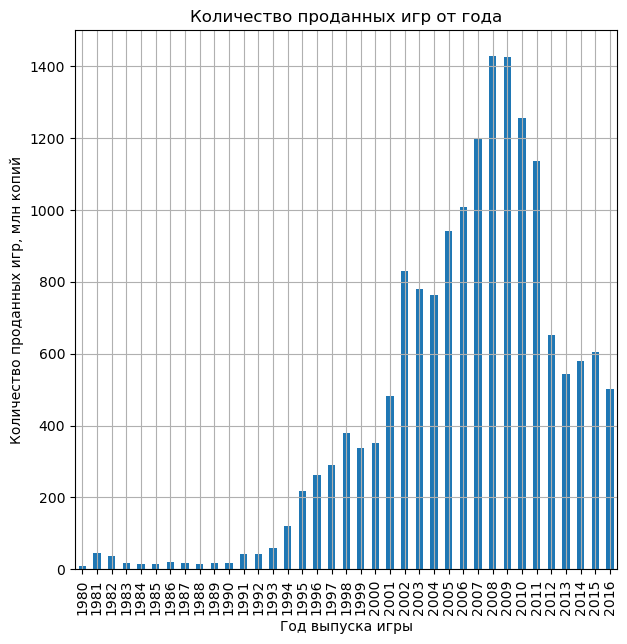

In [22]:
(#Рисуем сколько игр выпскалось в разные годы
    data.pivot_table(index='year_of_release', values='name', aggfunc='count')
    .plot(kind='bar', grid=True, figsize=(7, 7), title='Количество проданных игр от года', xlabel='Год выпуска игры', ylabel='Количество проданных игр, млн копий').legend().remove()
);

Как видно из диаграммы выше основная часть продаж находится в районе 1995 - 2016 года. За пределами 2000-х смысла анализировать данные нет. Слишком мало там продаж и было это очень давно

In [23]:
#Найдем топ 5 продаваемых платформ за все года
platform_top_5 = data.pivot_table(index='platform', values='total_sales', aggfunc='sum').sort_values(by='total_sales', ascending=False).head(5).reset_index()
for i in platform_top_5['platform']:
    platform_top_5.loc[platform_top_5['platform'] == i, 'max'] = data.loc[data['platform'] == i, 'year_of_release'].max()
    platform_top_5.loc[platform_top_5['platform'] == i, 'min'] = data.loc[data['platform'] == i, 'year_of_release'].min()
platform_top_5['liftime'] = platform_top_5['max'] - platform_top_5['min']
platform_top_5

,platform,total_sales,max,min,liftime
0,PS2,1247.28,2011.0,2000.0,11.0
1,X360,961.30,2016.0,2005.0,11.0
2,PS3,931.34,2016.0,2006.0,10.0
3,Wii,891.18,2016.0,2006.0,10.0
4,DS,802.79,2013.0,1985.0,28.0


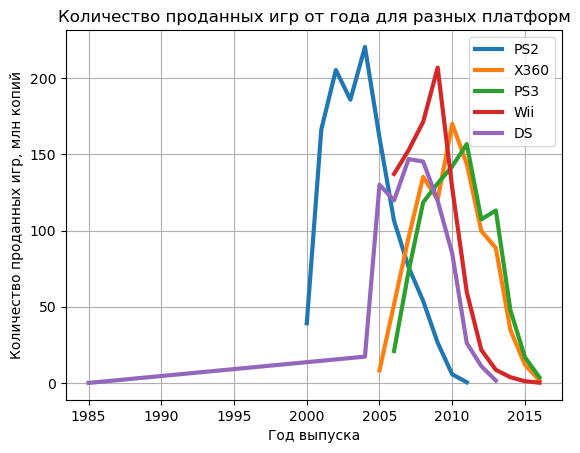

In [24]:
#Нарисуем зависимость продаж по годам для этих пяти платформ
s_platform = platform_top_5.loc[0, 'platform']
ax = data.query("platform == @s_platform").groupby('year_of_release')['total_sales'].sum().plot(label=s_platform, legend=True, grid=True, linewidth=3,  title='Количество проданных игр от года для разных платформ', xlabel='Год выпуска игры', ylabel='Количество проданных игр, млн копий')
for i in range(1, 5):
    s_platform = platform_top_5.loc[i, 'platform']
    (
        data.query("platform == @s_platform")
        .groupby('year_of_release')['total_sales'].sum().plot(label=s_platform, linewidth=3, legend=True, ax=ax, grid=True)
    )

plt.xlabel('Год выпуска');

Из графика выше и таблицы видно, что в среднем время жизни платформы составляет около 11 лет, данные по DS за 1985 год, скорее всего, является ошибкой, но по графику всё равно можно понять, что его реальный жизненный цикл не превосходит 11 годам

Рассмотрим данные за прошедшие 4 года, для выявления динамики

In [25]:
#Найдем срез данных по 11 годам
data_actual = data.query('year_of_release > 2012')
data_actual_pivot = data_actual.pivot_table(index='platform', columns='year_of_release', values='total_sales', aggfunc='sum').fillna('-')
for i in data_actual_pivot.index:
    data_actual_pivot.loc[i, 'Total'] = data_actual.loc[data_actual['platform'] == i, 'total_sales'].sum()
data_actual_pivot = data_actual_pivot.sort_values(by='Total', ascending=False)
data_actual_pivot

year_of_release,2013,2014,2015,2016,Total
platform,,,,,
PS4,25.99,100.0,118.9,69.25,314.14
PS3,113.25,47.76,16.82,3.6,181.43
XOne,18.96,54.07,60.14,26.15,159.32
3DS,56.57,43.76,27.78,15.14,143.25
X360,88.58,34.74,11.96,1.52,136.80
WiiU,21.65,22.03,16.35,4.6,64.63
PC,12.38,13.28,8.52,5.25,39.43
PSV,10.59,11.9,6.25,4.25,32.99
Wii,8.59,3.75,1.14,0.18,13.66


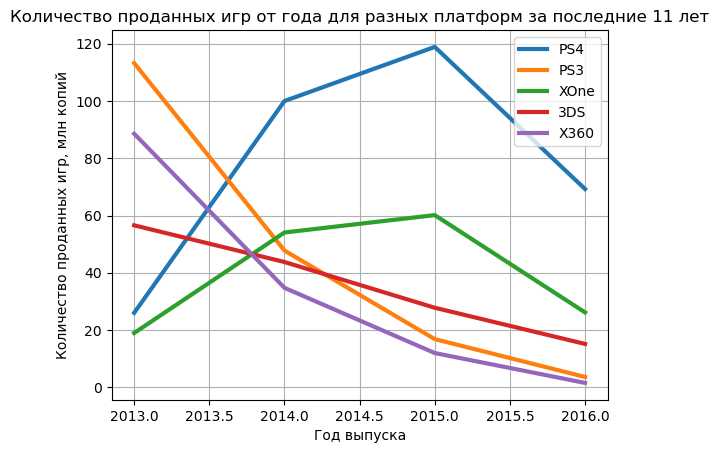

In [26]:
#Нарисуем зависимость топ пяти платформ по прадажам за последние 11 годам
s_platform = data_actual_pivot.index[0]
ax = data_actual.query('platform == @s_platform').groupby('year_of_release')['total_sales'].sum().plot(label=s_platform, legend=True, grid=True, linewidth=3,  title='Количество проданных игр от года для разных платформ за последние 11 лет', xlabel='Год выпуска игры', ylabel='Количество проданных игр, млн копий')
for i in range(1, 5):
    s_platform = data_actual_pivot.index[i]
    (
        data_actual.query('platform == @s_platform')
        .groupby('year_of_release')['total_sales'].sum().plot(label=s_platform, linewidth=3, legend=True, ax=ax, grid=True)
    )


plt.xlabel('Год выпуска');


Как видно из графика лидерами продаж являются PS4, PS3 и XOne. График имеет тенденцию к снижению, со временем, график чуть изменится за счёт последующих с годами продажах, скорее всего это связано с тем, что со времени 2015 года прошло еще не так много лет и за последующие пару лет зависимость изменится в лучшую сторону. Более наглядная картина была бы при выявлении зависимости продаж в каждом году, а не от года выпуска игры. Также можно видеть, что продажи по PS3 и X360 снижаются вместе с ростом PS4 и XOne. Это, скорее всего, связано с выходом новой версии платформы

In [27]:
#Построим сводную информацию по топ 3 платформам
data_actual_top = data_actual
data_actual_top.pivot_table(index='name', columns='platform', values='total_sales', aggfunc='sum').describe()

platform,3DS,DS,PC,PS3,PS4,PSP,PSV,Wii,WiiU,X360,XOne
count,303.000000,8.000000,189.000000,345.000000,392.000000,67.000000,358.000000,23.000000,115.000000,186.000000,247.000000
mean,0.472772,0.192500,0.208624,0.525884,0.801378,0.052239,0.092151,0.593913,0.562000,0.735484,0.645020
std,1.381347,0.172026,0.352304,1.451939,1.609456,0.059768,0.153816,0.915432,1.038778,1.663275,1.036139
min,0.010000,0.030000,0.010000,0.010000,0.010000,0.010000,0.010000,0.010000,0.010000,0.010000,0.010000
25%,0.040000,0.067500,0.030000,0.040000,0.060000,0.015000,0.020000,0.045000,0.060000,0.080000,0.060000
50%,0.090000,0.150000,0.080000,0.150000,0.200000,0.020000,0.040000,0.180000,0.200000,0.265000,0.220000
75%,0.280000,0.252500,0.230000,0.510000,0.730000,0.070000,0.110000,0.755000,0.595000,0.795000,0.685000
max,14.600000,0.510000,3.050000,21.050000,14.630000,0.240000,1.960000,3.580000,7.090000,16.270000,7.390000


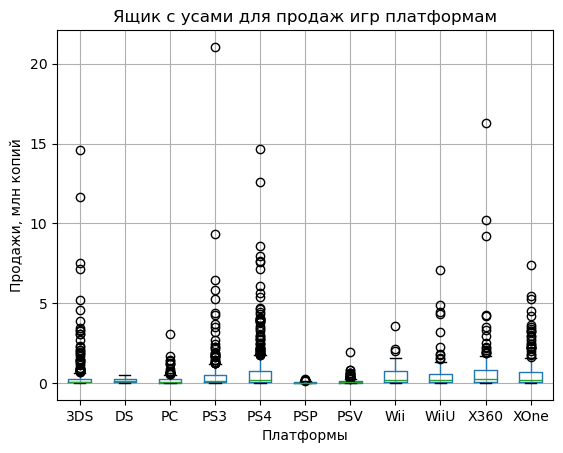

In [28]:
(
    data_actual_top
    .pivot_table(index='name', columns='platform', values='total_sales', aggfunc='sum')
    .boxplot()
);

plt.title('Ящик с усами для продаж игр платформам');
plt.xlabel('Платформы');
plt.ylabel('Продажи, млн копий');


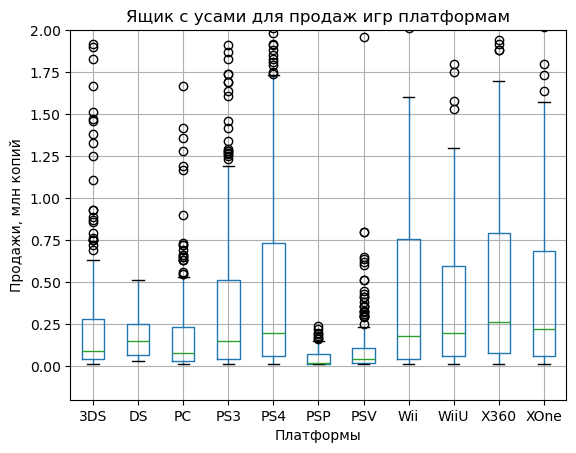

In [29]:
(
    data_actual_top
    .pivot_table(index='name', columns='platform', values='total_sales', aggfunc='sum')
    .boxplot()
);
plt.ylim(-0.2, 2)
plt.title('Ящик с усами для продаж игр платформам');
plt.xlabel('Платформы');
plt.ylabel('Продажи, млн копий');

Из ящика с усами и его описания видно, что в медианные значения продаж платформ за последние 4 года находятся на уровне около 0.2 млн копий, наибольшими размахами обладают PS4, Wii, X360. Наблюдается большое количество выбросов, немногим искажающие средние значения продаж. Но, видимо, за счёт большего числа продаж на PS4, PS3 и XOne, эти три платформы выдают большие итоговые продажи

In [30]:
#Введем вспомогательную функцию
def correlation(platform):
    ax = data_actual[(data_actual['platform'] == platform) & (~data_actual['user_score'].isna())].sort_values(by='user_score').plot(kind='scatter', alpha=0.5, x='user_score', y='total_sales', legend=True, label="Оценки пользователей", xlabel='Рейтинг пользователей', ylabel='Количество проданных игр, млн копий', figsize=(15, 15));
    data_cor_user = data_actual.loc[(data_actual['platform'] == platform) & (~data_actual['user_score'].isna()), ['user_score', 'total_sales']].sort_values(by='user_score').reset_index(drop=True)
    data_cor_user['user_score']=data_cor_user['user_score'].astype('float')
    data_actual[data_actual['platform'] == platform].plot(kind='scatter', alpha=0.5, x='critic_score', y='total_sales', grid=True, legend=True, label="Оценки критиков", xlabel='Рейтинг критиков', ylabel='Количество проданных игр, млн копий', figsize=(15, 15));
    data_cor_critic = data_actual.loc[data_actual['platform'] == platform, ['critic_score', 'total_sales']].sort_values(by='critic_score').reset_index(drop=True)
    print(f"Корреляция для пользователей: {data_cor_user['total_sales'].corr(data_cor_user['user_score']):.{2}f} и критиков {data_cor_critic['total_sales'].corr(data_cor_critic['critic_score']):.{2}f}")

Корреляция для пользователей: -0.03 и критиков 0.41


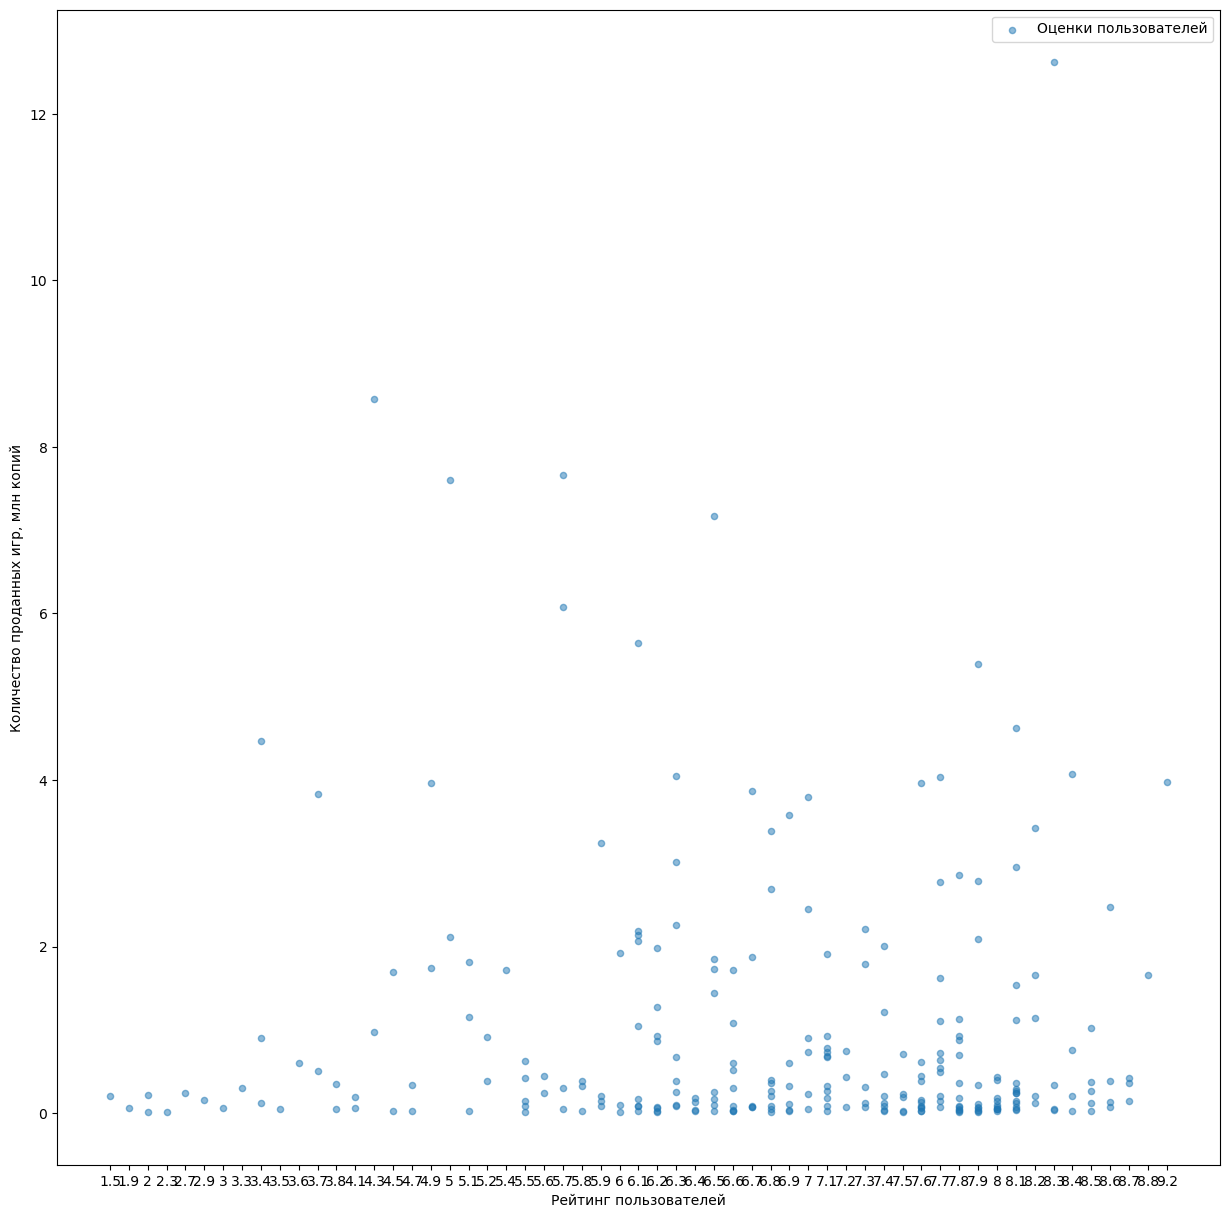

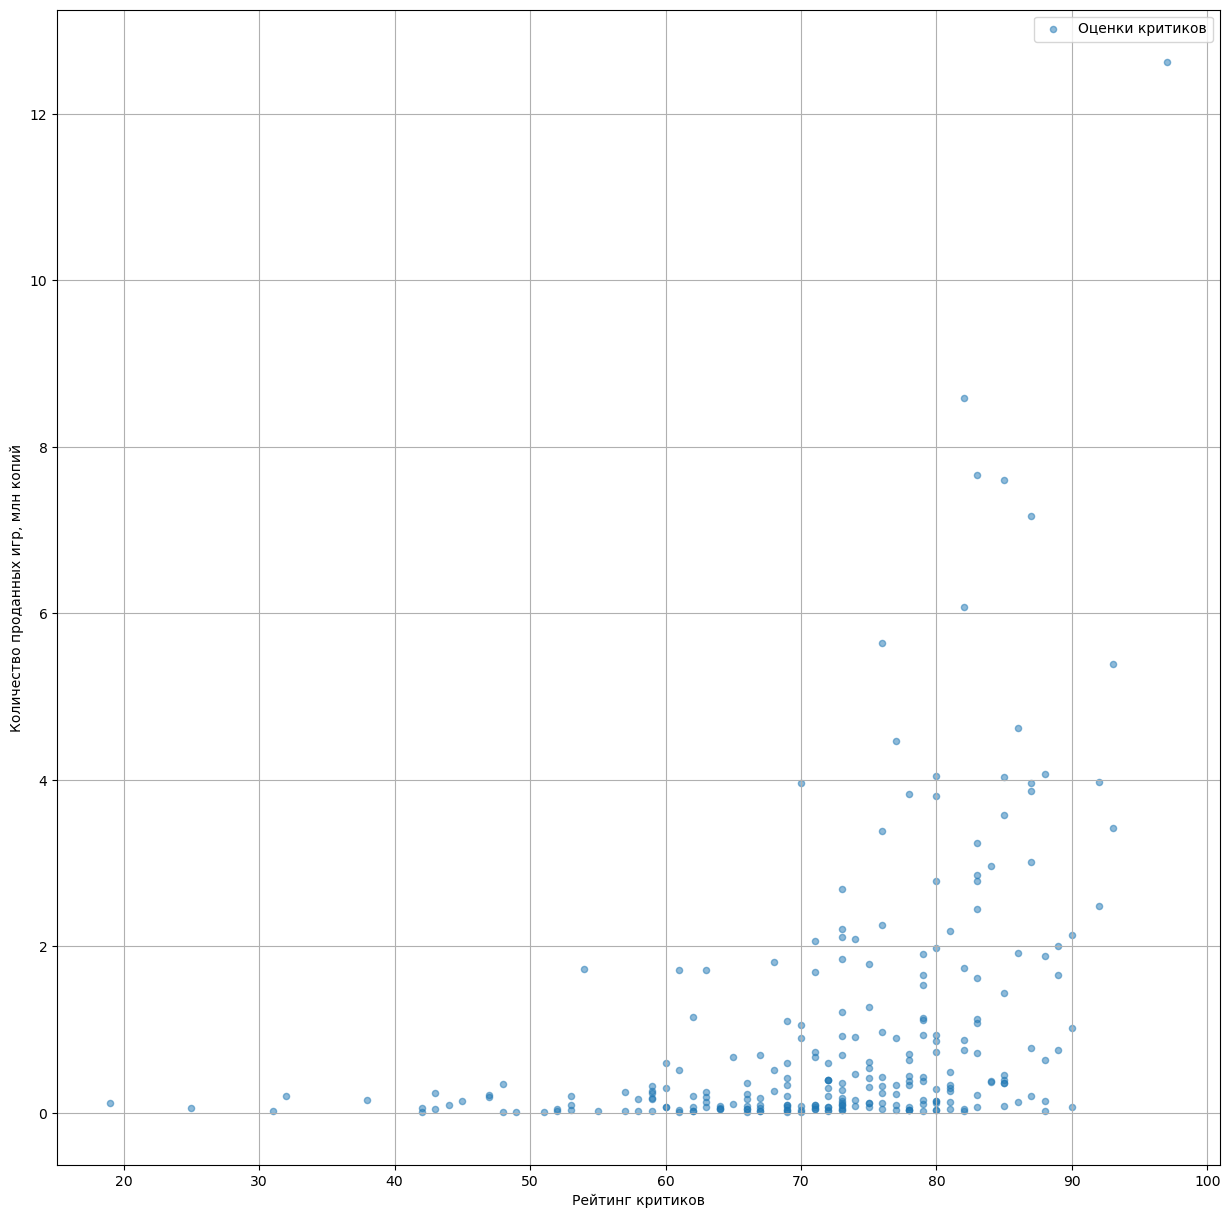

In [31]:
#Изучаем корреляции для разных платформ
correlation('PS4')

Корреляция для пользователей: 0.00 и критиков 0.33


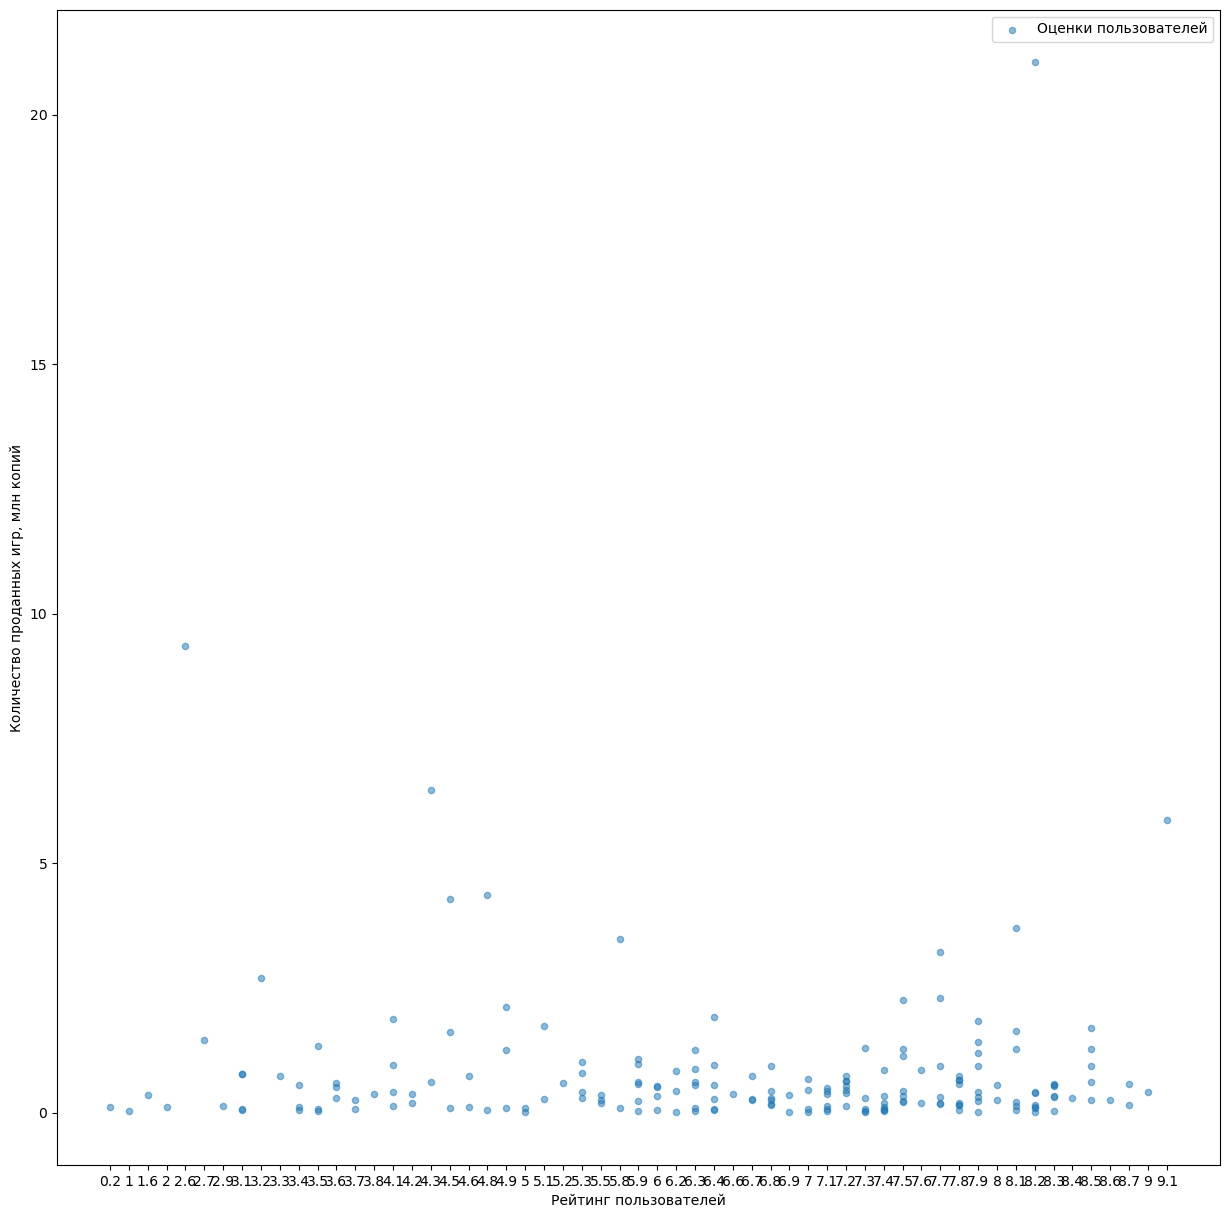

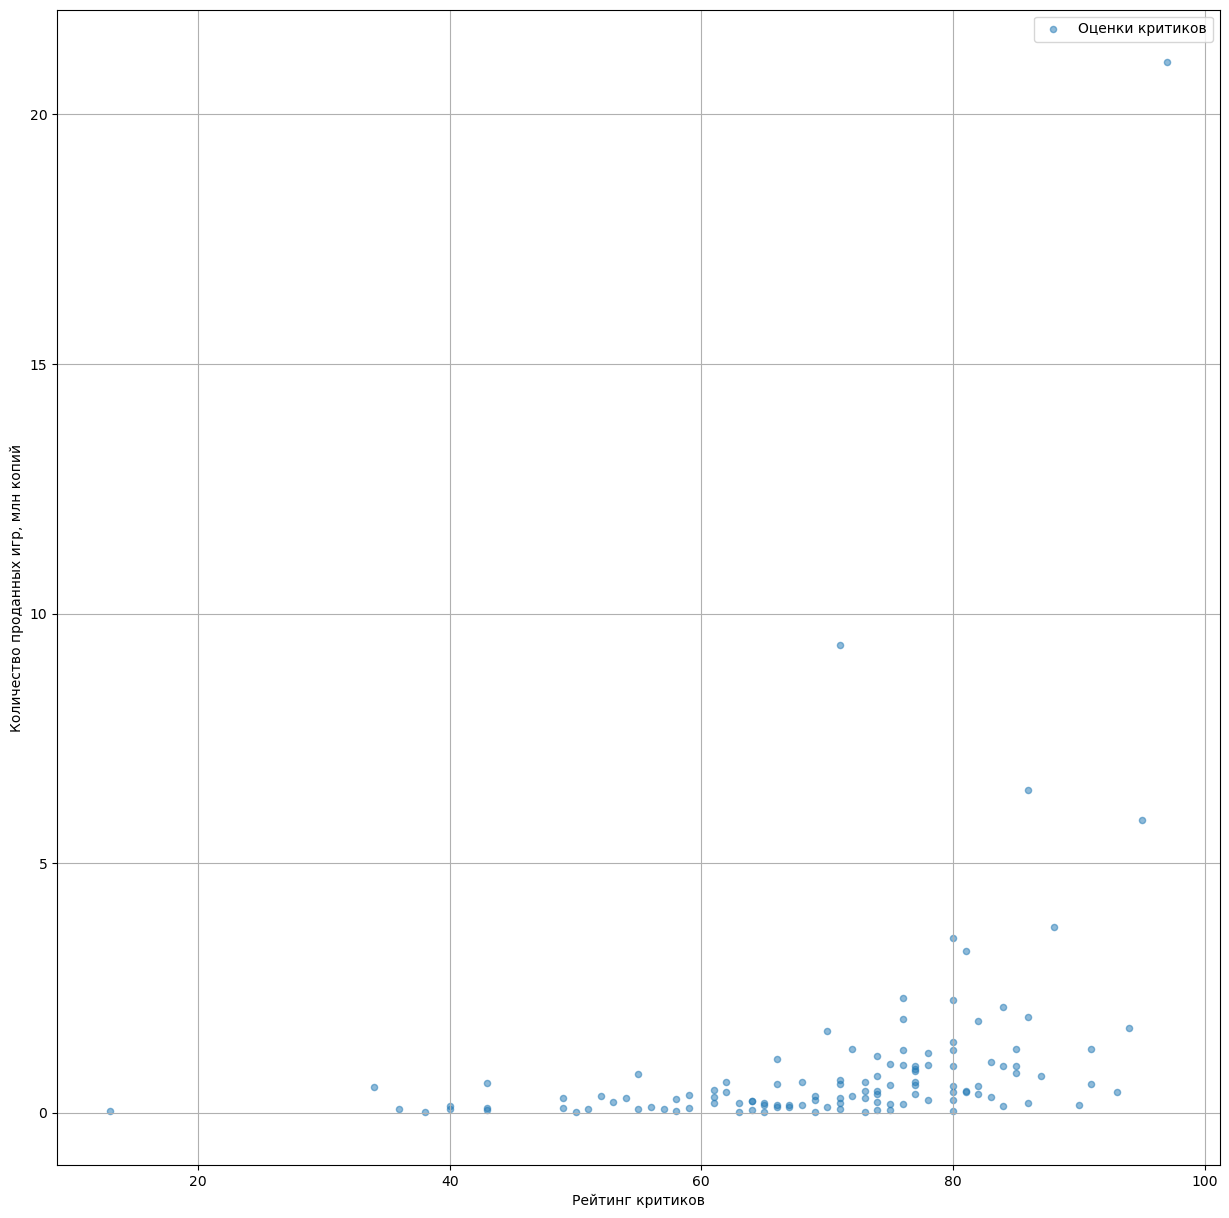

In [32]:
correlation('PS3')

Корреляция для пользователей: -0.07 и критиков 0.42


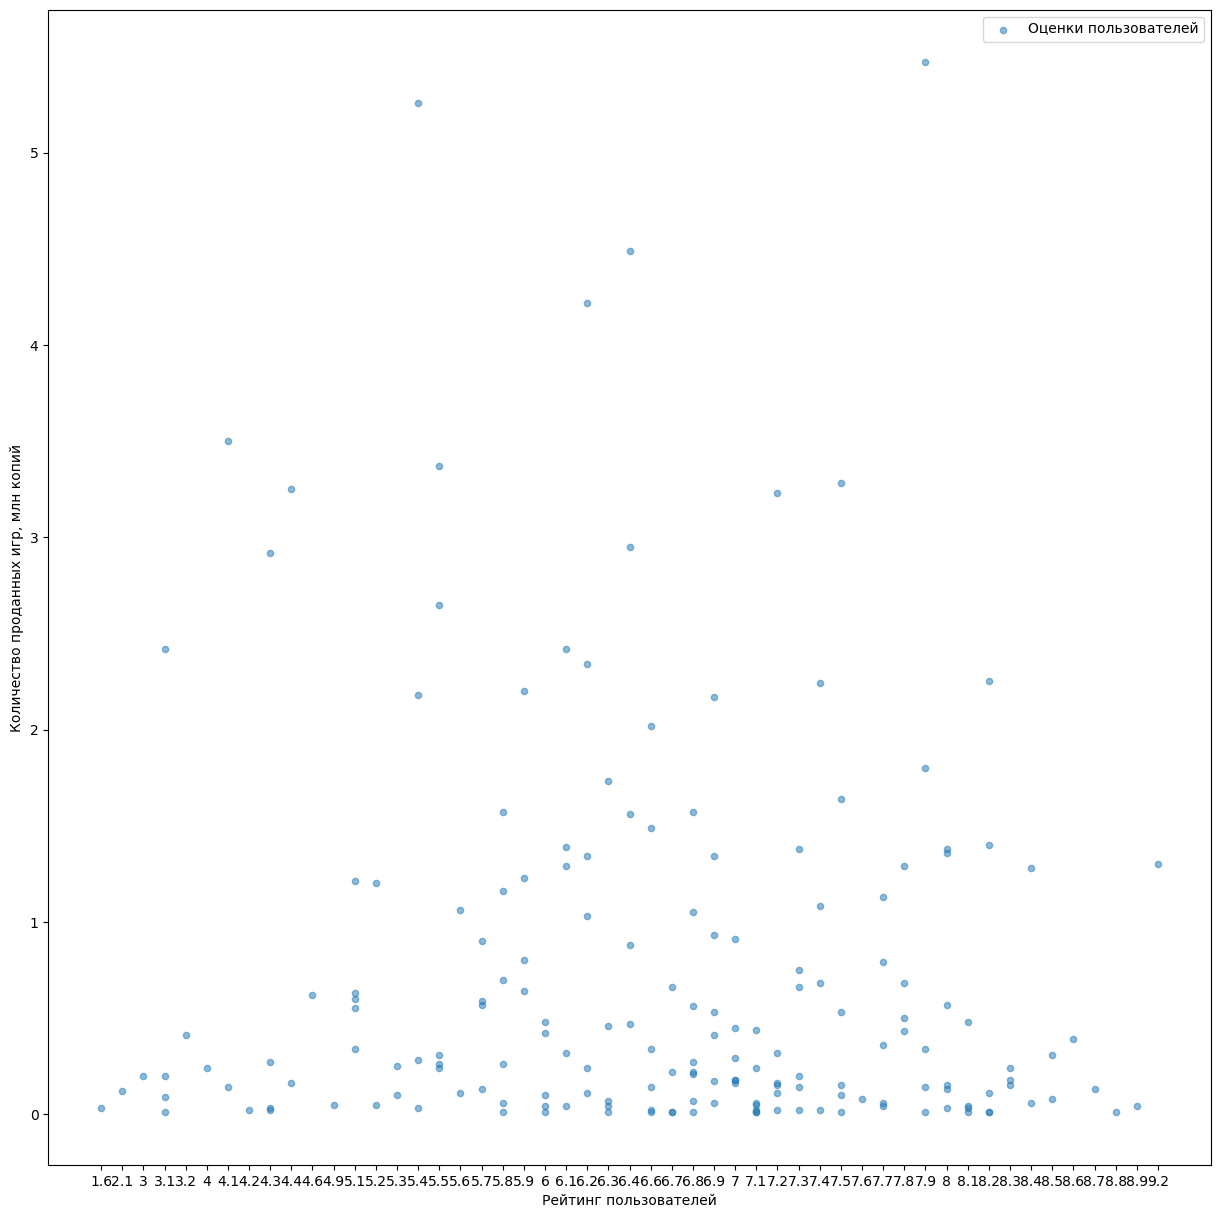

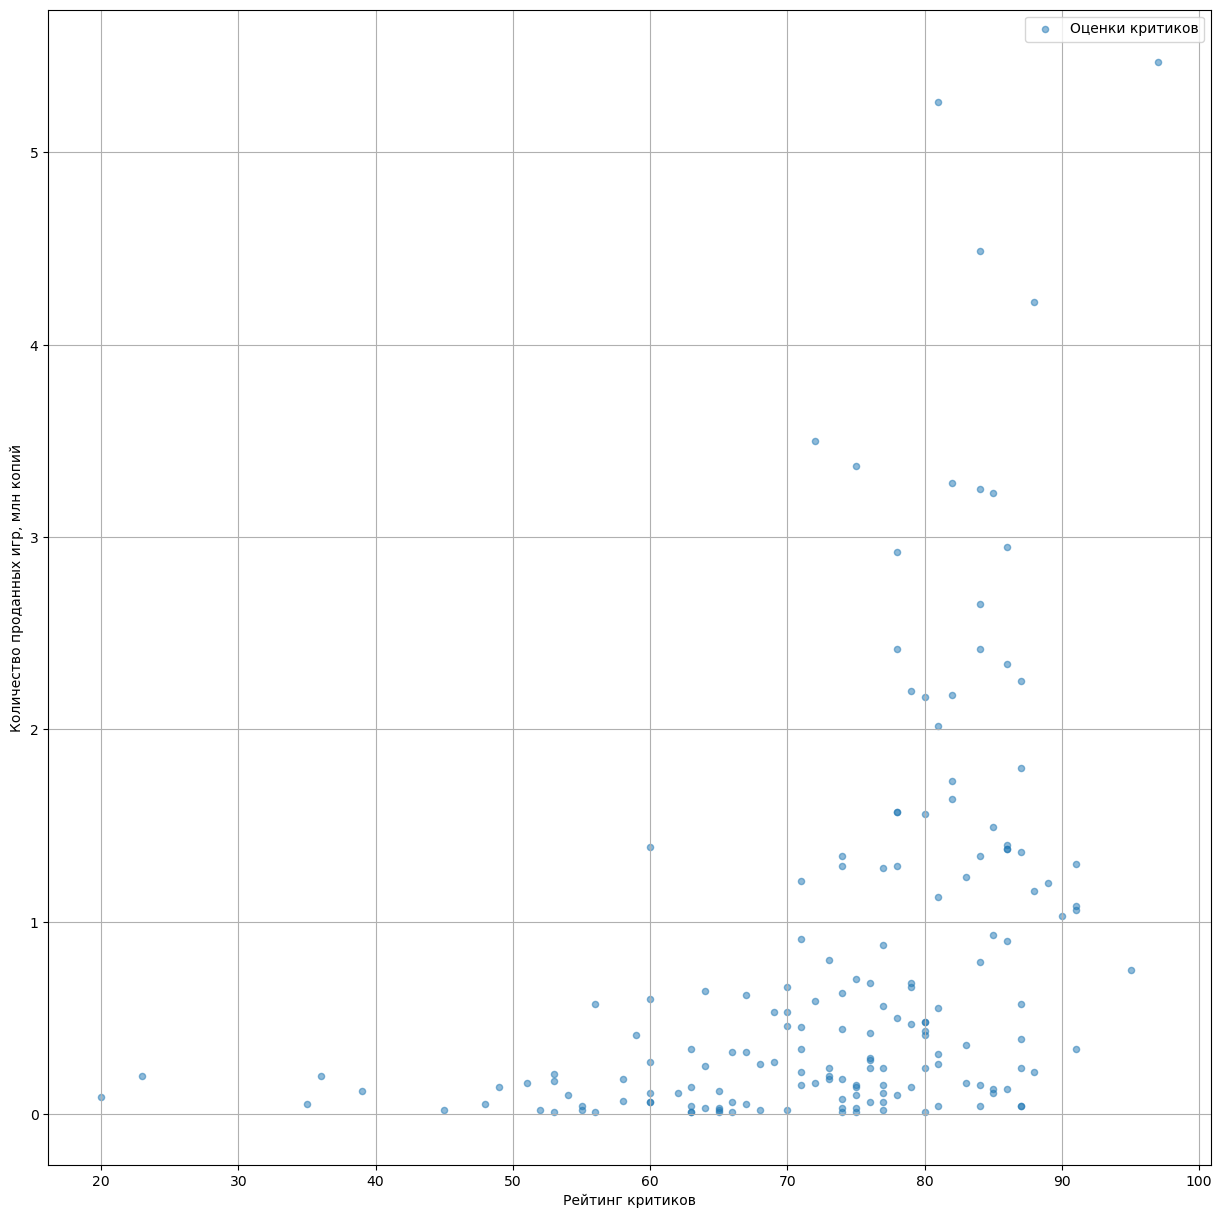

In [33]:
correlation('XOne')

Для топ трех платформ сильной корреляции для пользовательский отзывов не прослеживается, что значит, что люди покупают игры не сильно глядя на её рейтинги, зато отзывы критиков хоть и не сильно, но влияют на итоговую продажу, 

Корреляция для пользователей: -0.09 и критиков 0.20


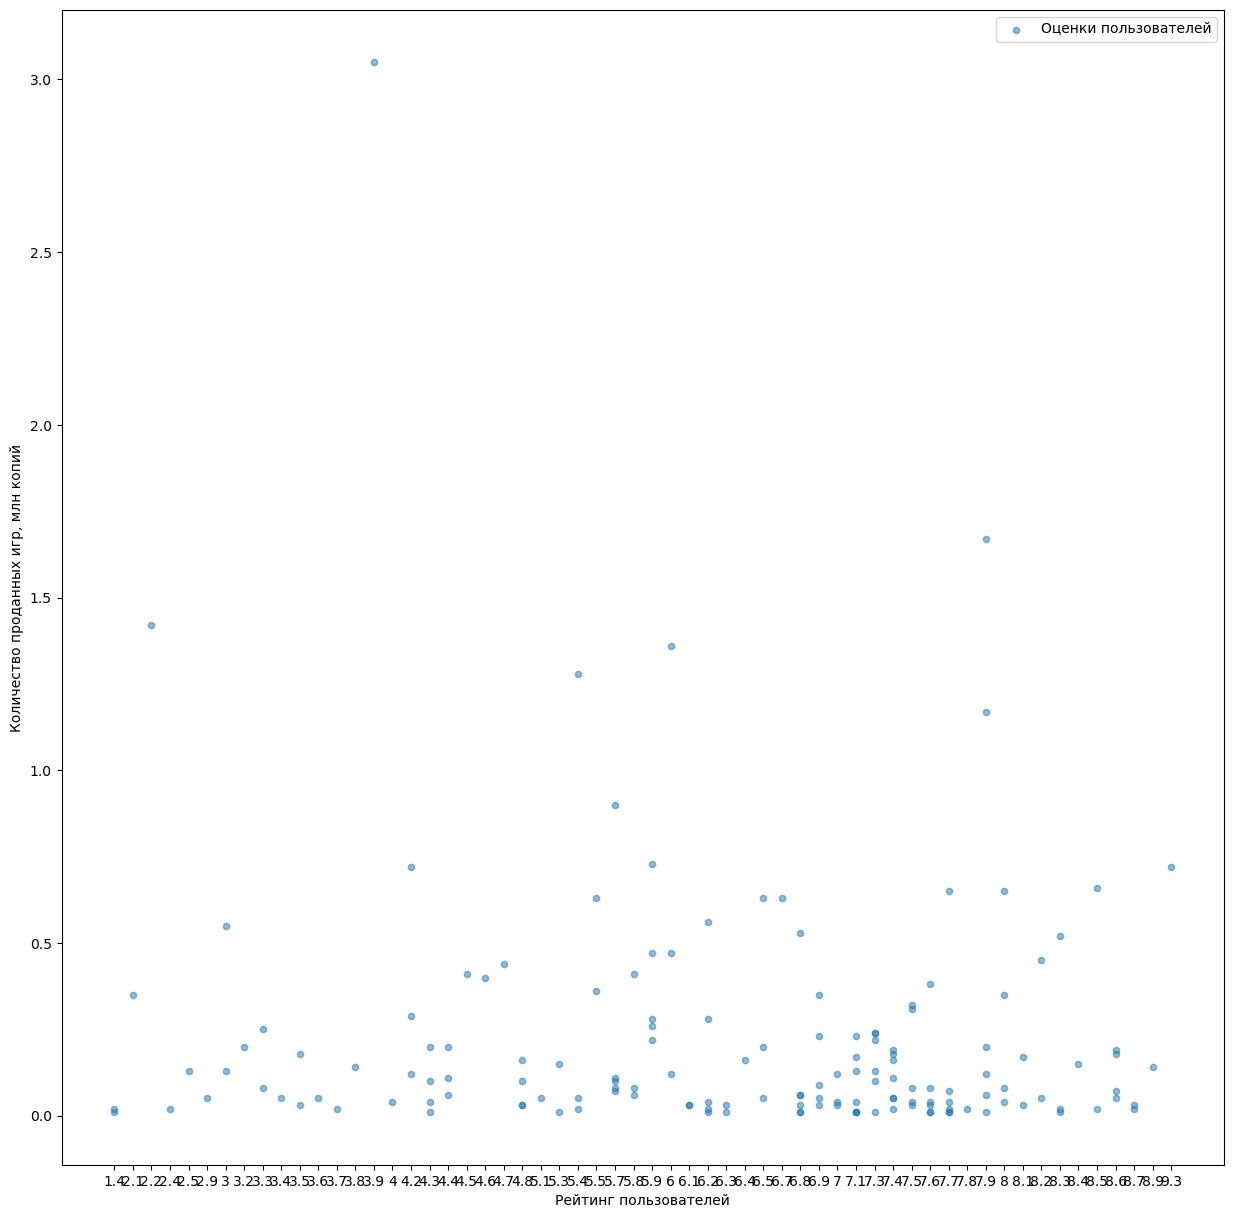

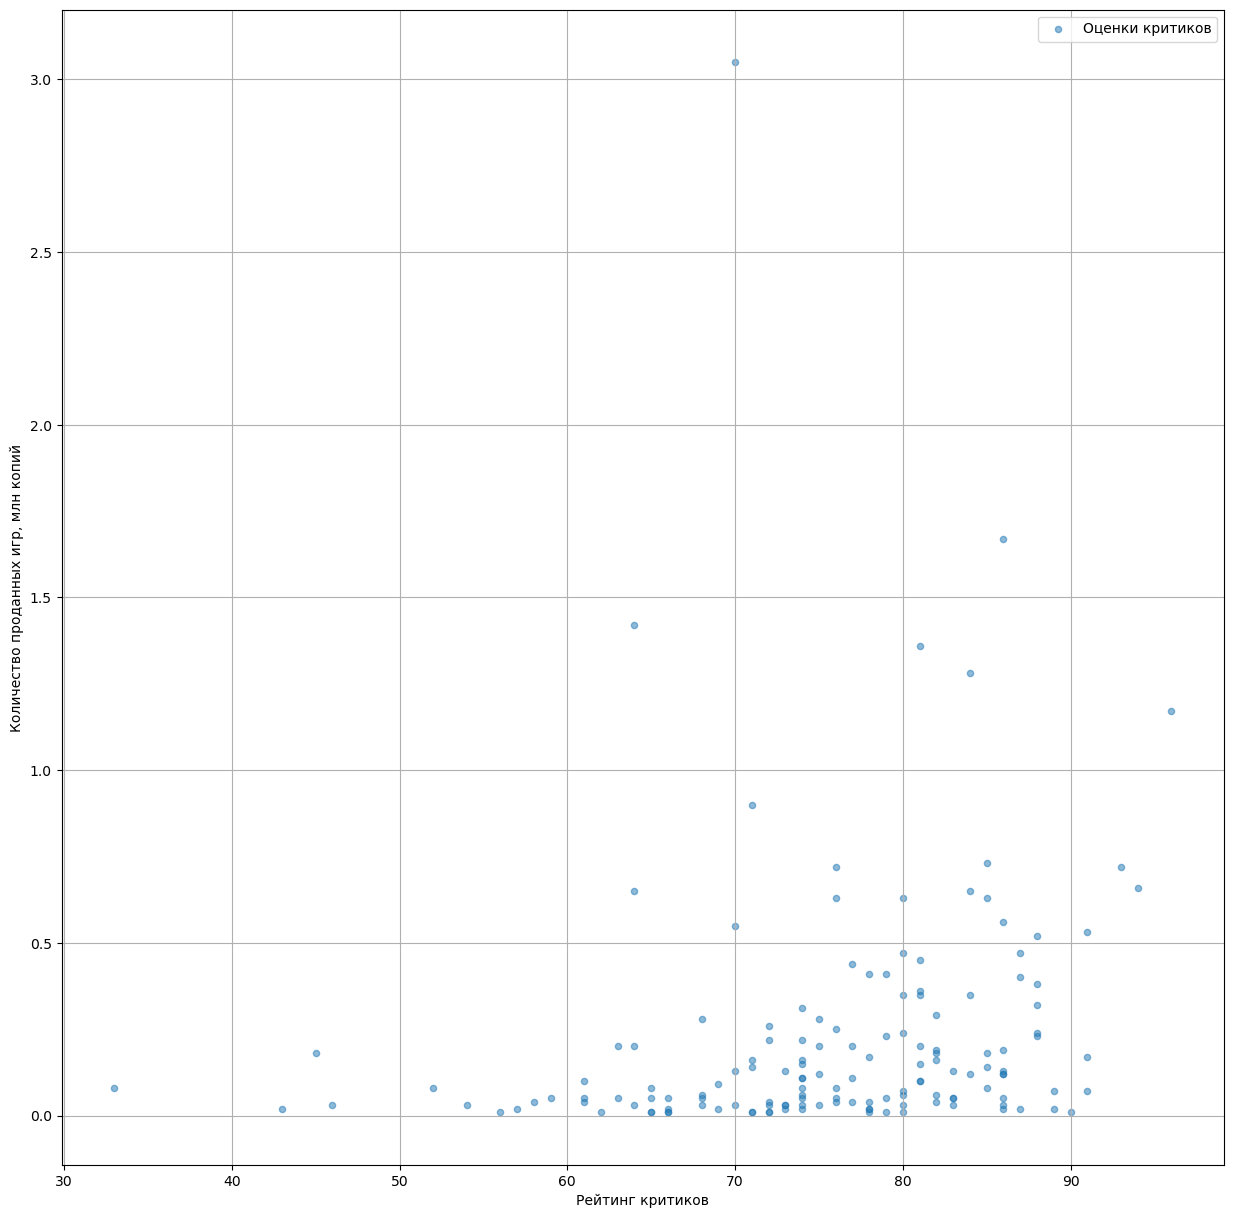

In [34]:
correlation('PC')

Корреляция для пользователей: -0.01 и критиков 0.35


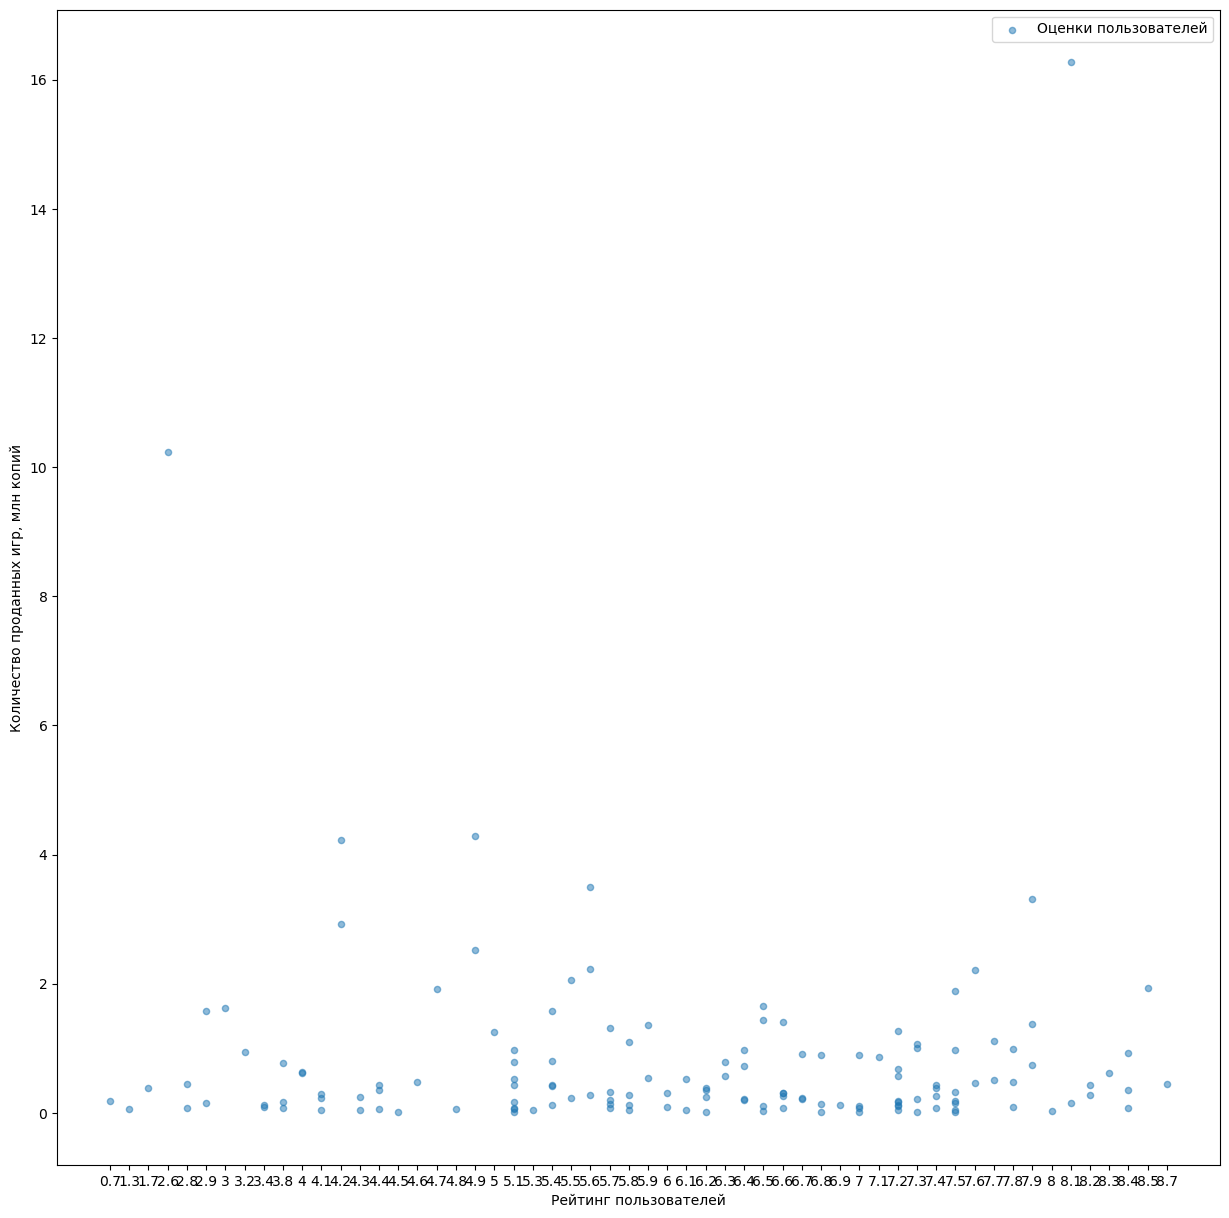

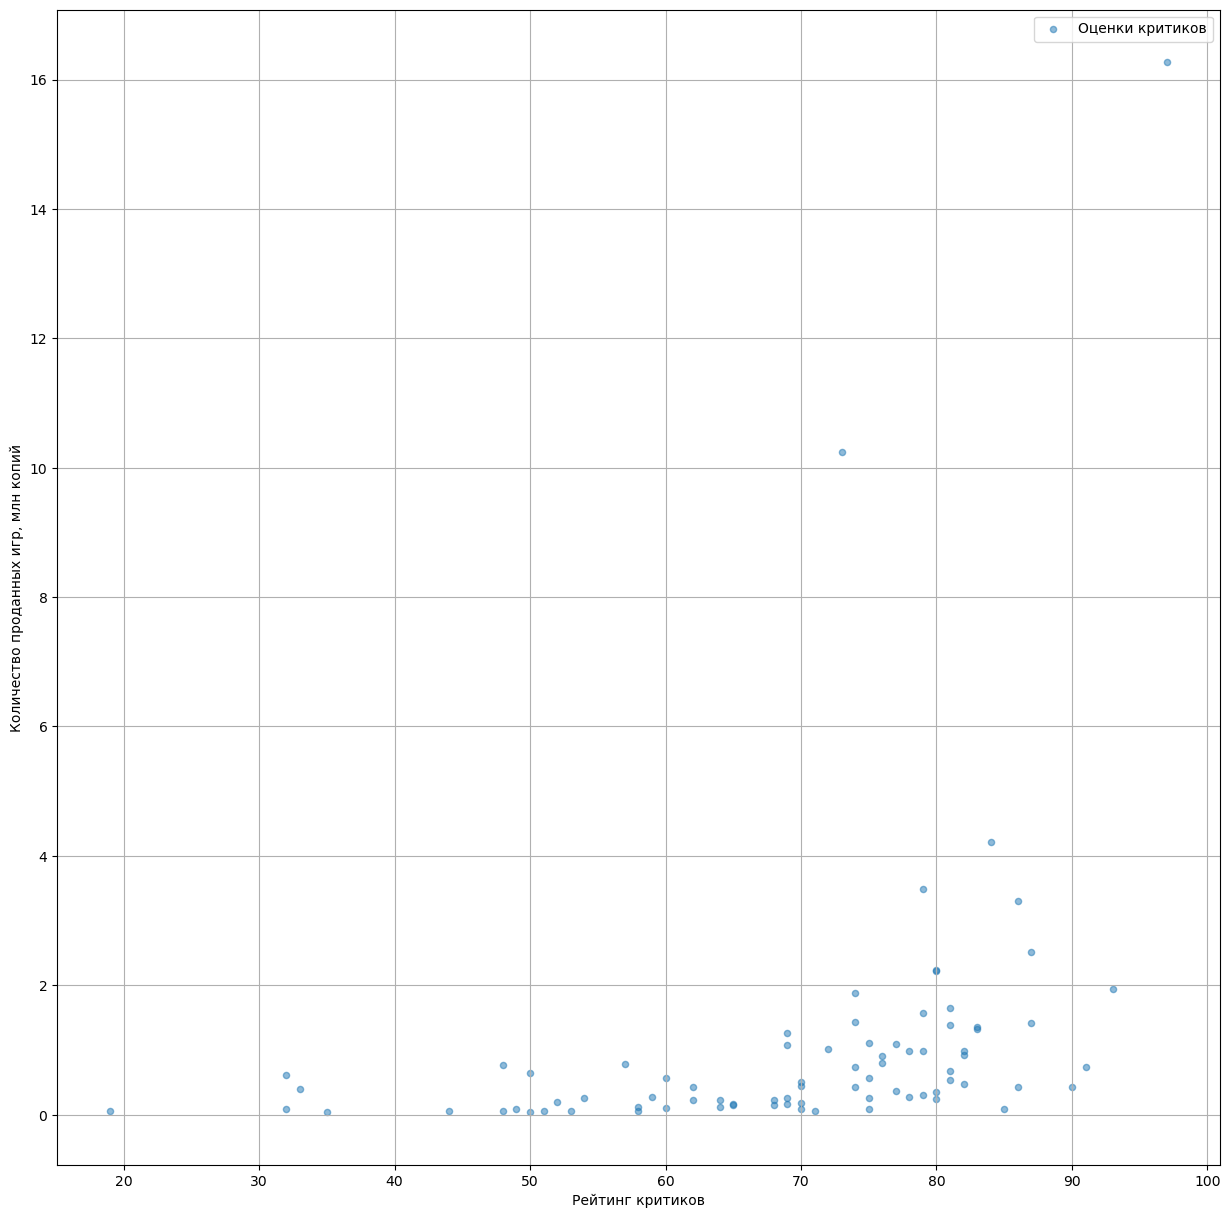

In [35]:
correlation("X360")

Для остальных платформ ситуация аналогичная. Выше приведены результаты для PC и X360, где корреляции по пользователям не наблюдается в отличии от корреляции по критикам 

Посмотрим на продажи топовых платформ по жанрам

In [36]:
data_actual_top.pivot_table(index='name', columns='genre', values='total_sales', aggfunc='sum').describe()

genre,Action,Adventure,Fighting,Misc,Platform,Puzzle,Racing,Role-Playing,Shooter,Simulation,Sports,Strategy
count,402.000000,179.000000,47.000000,102.000000,37.000000,12.000000,36.000000,207.000000,76.000000,48.000000,75.000000,42.000000
mean,0.800672,0.132067,0.751277,0.615882,1.152162,0.264167,1.108056,0.704783,3.065526,0.453333,2.008667,0.240000
std,3.177224,0.367532,1.943517,2.528428,1.361252,0.369089,1.546433,1.820247,5.362747,1.004601,3.761598,0.395018
min,0.010000,0.010000,0.010000,0.010000,0.010000,0.010000,0.010000,0.010000,0.010000,0.010000,0.020000,0.010000
25%,0.030000,0.020000,0.055000,0.030000,0.190000,0.027500,0.097500,0.060000,0.140000,0.027500,0.170000,0.030000
50%,0.110000,0.030000,0.170000,0.090000,0.580000,0.090000,0.470000,0.160000,1.190000,0.050000,0.530000,0.085000
75%,0.410000,0.070000,0.520000,0.275000,1.730000,0.285000,1.552500,0.480000,3.550000,0.367500,1.470000,0.247500
max,56.580000,2.920000,12.420000,24.160000,6.000000,1.190000,7.090000,14.600000,27.390000,5.220000,17.370000,1.730000


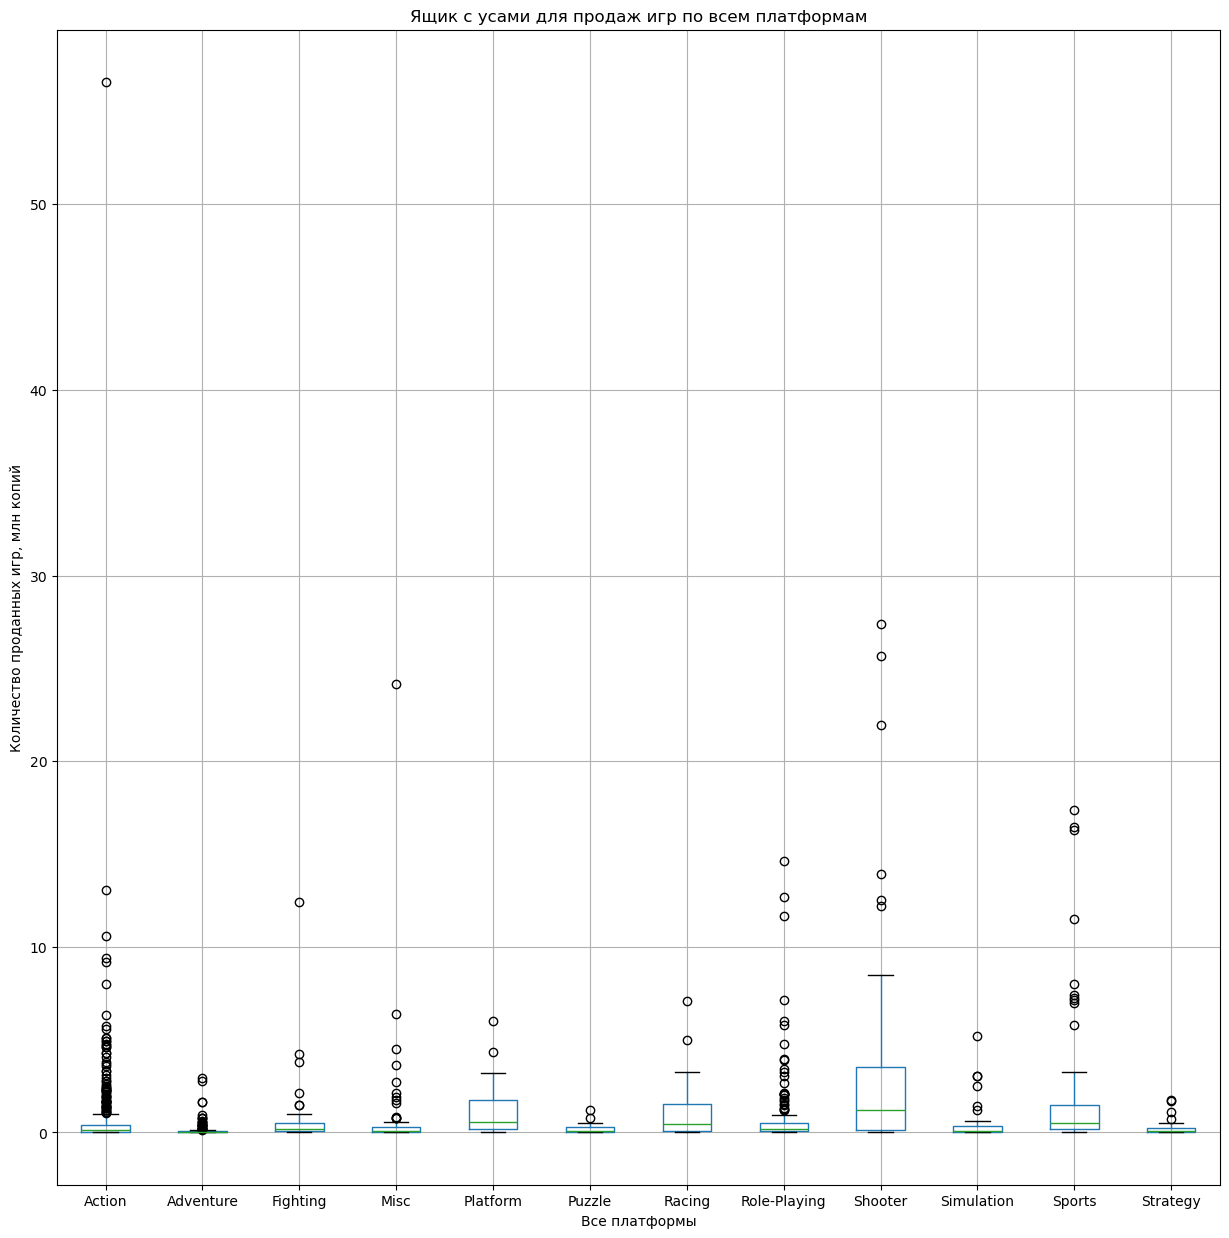

In [37]:
(
    data_actual_top
    .pivot_table(index='name', columns='genre', values='total_sales', aggfunc='sum')
    .boxplot(figsize=(15, 15))
);
plt.title('Ящик с усами для продаж игр по всем платформам');
plt.xlabel('Все платформы');
plt.ylabel('Количество проданных игр, млн копий');

Из таблицы выше и графика можно сказать, что люди предпочитают играть в шутеры и спортивные игры, это видно по их мединным значениям и размахом, и они менее заинтересованы в головоломках и стратегиях, что, вполне, ожидаемо, поскольку шутеры ориентированы на более широкий класс людей. На графике видно большое количество выбросов, особенно для экшен игр. 

## Шаг четвёртый. Портрет пользователя по регионам

In [38]:
#Создадим вспомогательную функцию
def pivot_sales(index, region):
    data_sales = data_actual.pivot_table(index=index, values=region, aggfunc='sum').sort_values(by=region, ascending=False)
    data_sales['fraction'] = data_sales[region] / data_sales[region].sum() * 100
    return data_sales.head()

In [39]:
pivot_sales('platform', 'na_sales')

,na_sales,fraction
platform,,
PS4,108.74,24.842933
XOne,93.12,21.274360
X360,81.66,18.656188
PS3,63.50,14.507322
3DS,38.20,8.727239


In [40]:
pivot_sales('genre', 'na_sales')

,na_sales,fraction
genre,,
Action,126.05,28.797606
Shooter,109.74,25.071394
Sports,65.27,14.911700
Role-Playing,46.40,10.600626
Misc,27.49,6.280414


In [41]:
pivot_sales('rating', 'na_sales')

,na_sales,fraction
rating,,
M,165.21,37.744169
unknown,89.42,20.429051
E,79.05,18.059903
E10+,54.24,12.391766
T,49.79,11.375111


Для Северной Америки наиболее популярной платформой является PS4, XOne и X360, составляющие около половины всего рынка в регионе.

Наиболее интересные для них жанры - это экшен игры, шутеры и спорт.

Рейтинг же играет, довольно, существуенную роль в продаваемости игр в регионе. В категории M проданы около 16. млн копий, что составляет 38% рынка, а для категории T - 50 млн (11%).

In [42]:
pivot_sales('platform', 'eu_sales')

,eu_sales,fraction
platform,,
PS4,141.09,35.971241
PS3,67.81,17.288326
XOne,51.59,13.152997
X360,42.52,10.840578
3DS,30.96,7.893328


In [43]:
pivot_sales('genre', 'eu_sales')

,eu_sales,fraction
genre,,
Action,118.13,30.117533
Shooter,87.86,22.400122
Sports,60.52,15.429722
Role-Playing,36.97,9.425592
Racing,20.19,5.147490


In [44]:
pivot_sales('rating', 'eu_sales')

,eu_sales,fraction
rating,,
M,145.32,37.049690
E,83.36,21.252836
unknown,78.91,20.118298
E10+,42.69,10.883920
T,41.95,10.695255


Европейский рынок немногим отличается от американского. Наиболее популярные платформы здесь - это PS4, PS3 и XOne. Популярные же жанры такие же как и у американского рынка, здесь в топе: экшен игры, шутеры и спорт. Рейтинг здесь также играет существуенную роль в тех же пропорциях

In [45]:
pivot_sales('platform', 'jp_sales')

,jp_sales,fraction
platform,,
3DS,67.81,48.167353
PS3,23.35,16.586163
PSV,18.59,13.205001
PS4,15.96,11.336838
WiiU,10.88,7.728371


In [46]:
pivot_sales('genre', 'jp_sales')

,jp_sales,fraction
genre,,
Role-Playing,51.04,36.255150
Action,40.49,28.761188
Misc,9.20,6.535019
Fighting,7.65,5.434011
Shooter,6.61,4.695269


In [47]:
pivot_sales('rating', 'jp_sales')

,jp_sales,fraction
rating,,
unknown,85.05,60.413411
T,20.59,14.625657
E,15.14,10.754369
M,14.11,10.022731
E10+,5.89,4.183833


Японский же рынок отличается от предыдущих двух. Это связано, скорее всего, с культурными различиями между регионами. 

В топ продажам по платформам здесь фигурируют 3DS, PS3 и PSV, а по жанрам первые три - это ролевые игры, экшен игры и misc.

Рейтинг же здесь не имеет большой силы. Большинство рейтинга - unknown, связано это с тем, что данная классификация в регионе не популярна, остальные же рейтинги T, E, M покупаются в пропорциях около (10 - 14)%

## Шаг пятый. Проверка гипотез

In [48]:
#Проверим гипотезу о том, что в среднем пользовательские рейтинги в XOne и PC одинаковые
xOne = data_actual.loc[(data_actual['platform'] == 'XOne') & (~data_actual['user_score'].isna()), 'user_score'].astype('float')
PC = data_actual.loc[(data_actual['platform'] == 'PC') & (~data_actual['user_score'].isna()), 'user_score'].astype('float')
hypoteses1 = st.ttest_ind(xOne, PC, equal_var=False, alternative='two-sided')
hypoteses1.pvalue

np.float64(0.14759594013430463)

In [49]:
print(f'{xOne.mean():.{2}f} +- {xOne.std()/math.sqrt(xOne.count()):.{2}f}')

6.52 +- 0.10


In [50]:
print(f'{PC.mean():.{2}f} +- {PC.std()/math.sqrt(xOne.count()):.{2}f}')

6.27 +- 0.13


Для проверки этой гипотезы были исследованы методом ttest_ind два датасета пользовательский отзывов в двух платформах. Так как выборки разные и рейтинги по разным платформам сопадать не должны, используем разные дисперсии для двух распределений. Используем двухсторонюю гипотезу, где нулевая гипотеза - равенство двух средний значений в распределениях, а альтернативная - средние значения не равны друг другу.

Видно, что pvalue около 15%, что больше типичного значения статистической значимости в 5%, поэтому нулевую гипотезу мы отвергнуть не можем. Пользовательские рейтинги игры в этих двух платформах со статистической значимостью в 5% одинаковые.

Для проверки выше были посчитаны средние значения, где видно что они находятся близко друг другу на уровне 2 * ESE/sqrt(n)

In [51]:
#Проверим гипотезу о том, что в среднем пользовательские рейтинги в жанре экшен и спорт различны
Action = data_actual.loc[(data_actual['genre'] == 'Action') & (~data_actual['user_score'].isna()), 'user_score'].astype('float')
Sports = data_actual.loc[(data_actual['genre'] == 'Sports') & (~data_actual['user_score'].isna()), 'user_score'].astype('float')
hypoteses2 = st.ttest_ind(Action, Sports, equal_var=False, alternative='two-sided')
hypoteses2.pvalue

np.float64(1.4460039700704315e-20)

In [52]:
print(f'{Action.mean():.{2}f} +- {Action.std()/math.sqrt(xOne.count()):.{2}f}')

6.84 +- 0.10


In [53]:
print(f'{Sports.mean():.{2}f} +- {Sports.std()/math.sqrt(xOne.count()):.{2}f}')

5.24 +- 0.13


В данном случае аналогично применяем метод ttest_ind для проверки двухсторонней гипотезы. Нулевая гипотеза - пользовательские рейтинги жанров Action и Sport равны друг другу, альтернативная - рейтинги разные.

Так как pvalue много меньше 5%, то нулевую гипотезу отвергаем в пользу альтернативной. Пользовательские рейтинги игр в этих двух жанрах разные.

Для проверки выше были посчитаны средние значения, где видно что они находятся далеко друг другу более 5 * ESE/sqrt(n)

## Шаг шестой. Вывод

В данной работы был проанализирован рынок продаж видеоигр в интернет-магазине «Стримчик».

В первом шаге был успешно открыт и проанализирован датасет.

На втором шаге была выполнена предобработка данных. Были переименованы столбцы в более канонический вид, тип данных, за исключением даты выхода игры, везде верный, заменены пропуски. В столбцах отзывов критиков и пользователей пустые строки были осталены без изменений. В столбце год выпуска там где год игры написан в названии были заменены пропуски на соответствующее значение, остальные пропуски были удалены из-за их малого количества. Итого доля отсеянных строк составляет менее двух процентов, аномальных значений не обнаружено, отсеяны были также строки без жанра. Пустые строки в столбце rating обработаны не были в силу невозможности определения возрастного рейтинга для каждой из игр, они были заменены на unknown для дальнейшего анализа. В пользовательском рейтинге строки с tbd при анализе игнорировались, поскольку для этих игр оценка пользователей ещё не готова, но исключать эти данные из полного анализа нет смысла, они были заменены на NaN.

На третьем шаге был проведён исследовательский анализ данных. Было выявлено, что наибольшие продажи происходили в период от 1995 - 2016 года, до 1995 года рассматривать продажи смысла нет, так как это было давно и продажи там низкие. На примере топ5 продаваемых платформ было выявлено, что в среднем платформы живут около 11 лет. Так как время жизни большое, была сделана выборка данных за период от 2012 по 2016 года, где прослеживается динамика последний лет. За этот период топ3 платформ являются PS4, PS3 и One. К 2016 году продажи немного снижаются, но скорее всего это связано с тем, что со времени 2015 года прошло еще не так много лет и за следующие года зависимость в районе 2016 года изменится. Для вывода о том, снижаются ли продажи или нет, необходимы данные продаж за каждый год, а не продажи по году выпуска продукта.

Медианные значения продаж платформ за последние 4 года находятся на уровне около 0.2 млн копий, наибольшими размахами обладают PS4, Wii, X360. Наблюдается большое количество выбросов, немногим искажающие средние значения продаж. Но, видимо, за счёт большего числа продаж на PS4, PS3 и XOne, эти три платформы выдают большие итоговые продажи. Отзывы пользователей по всем платформам не сильно влияют на продаваемость товара, а вот отзывы критиков имеют большую силу. Для них коэффициент корреляции составляет около 0.3-0.4, что не много, но для продаж существенно. Самыми прибыльными жанрами являются шутеры игры, в то время как головоломки нравятся меньшему числу людей.

На четвертом шаге был выявлен портрет пользователя в каждом регионе. Было выявлено, что вкусы у американцев и европейцев немногим схожи. Они оба предпочитают экшен игры, шутеры игры и спорт. Америкцы предпочитают PS4, XOne и X360, а европейцы PS4, PS3 и XOne, в то время как из-за культурных различий, японцы предпочитают другую направленность. Они больше покупают ролевые игры, экшен игры и misc на платформах 3DS, PS3 и PSV. Для американского и европейского рынков рейтинг ESRB в значительном мере влияет на продаваемость игр, игры с рейтингом M занимает почит половину рынка, в то время как для японцев этот рейтинг почти ничего не значит.

На пятом шаге были проверены гипотезы о равенстве среднего рейтинга пользователей в платформе XOne и PC, где при сравнении с статистической значимостью в 5% было выявлено, что рейтинги одинаковые. В противовес этому при проверки гипотезе о равенстве пользовательского рейтинга в жанрах Action и Sports было выявлено с той же статистической значимостью, что они разные.

Таким образом, можно спрогнозировать, что в следующем году в европейском и американском регионах будет востребованы экшен игры, шутеры игры и спортивные игры, платформы PS4, XOne и X360 для америанцев и PS4, PS4 и XOne для европейцев с рейтингом M, а в японском регионе ролевые игры, экшен игры и misc на платформах 3DS, PS3 и PSV с любым рейтингом. Более внимательно на рекламной компании надо ориентироваться на мнение критиков при рекламировании той или иной игры, поскольку их мнение влияет на продаваемость.